<a href="https://colab.research.google.com/github/ihsann2410010447/projek-statistika-Akbar-Ihsan-Nugraha/blob/main/Milestone3_Sampling_CI_Power_2410010447_Akbar_Ihsan_Nugraha.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📝 Milestone 3 — Sampling Distribution, Confidence Interval & Power Analysis

**Mata Kuliah:** Statistika & Probabilitas (TIF1501) · CPMK072 (Sub-CPMK 072.2) · Milestone 3
**Nama / NIM:** _isi di sini_
**Dataset:** _nama dataset Milestone 1–2 Anda_

> **Cara pakai:** (1) isi sel **Konfigurasi** (path dataset, kolom metrik, kolom grup, MDE), (2) tulis interpretasi di sel markdown yang bertanda `_..._`, (3) jalankan semua sel.
> Secara default notebook memakai **data demo sintetis** agar langsung bisa dijalankan — ganti `DATA_PATH` untuk memakai dataset Anda.

Notebook ini mencakup 4 komponen Milestone 3: **(1)** simulasi sampling distribution, **(2)** CI rumus vs bootstrap + CI selisih 2 grup, **(3)** power analysis untuk MDE pilihan, **(4)** rekomendasi keputusan + catatan risiko.

# 🔧 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportion_confint, proportion_effectsize
from statsmodels.stats.power import NormalIndPower, TTestIndPower

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
rng = np.random.default_rng(42)
ALPHA = 0.05

# ⚙️ 2. Konfigurasi & Load Data

Dataset Anda tidak harus eksperimen A/B — pilih **2 grup penting** (mis. pelanggan premium vs reguler, wilayah A vs B) dan perlakukan sebagai perbandingan dua grup.

| Parameter | Arti |
|---|---|
| `METRIC` | kolom metrik utama — numerik **atau** biner 0/1 (terdeteksi otomatis) |
| `GROUP_COL`, `G1`, `G2` | kolom grup; `G1` = pembanding/kontrol, `G2` = perlakuan. Selisih dihitung **G2 − G1** |
| `MDE` | selisih terkecil yang **penting bagi bisnis**, dalam satuan metrik (biner: 0.01 = 1 poin persen) |
| `HIGHER_IS_BETTER` | `False` bila metrik makin kecil makin baik (mis. waktu muat, churn) |
| `EXPECTED_RATIO_G1` | proporsi ukuran grup G1 yang diharapkan (0.5 jika seimbang; ubah jika bukan eksperimen terencana) |

In [2]:
# ====== ISI BAGIAN INI ======
DATA_PATH = None            # contoh: "https://raw.githubusercontent.com/.../data.csv" atau "data.csv"

METRIC     = "belanja"      # numerik (mis. "belanja") atau biner 0/1 (mis. "beli")
GROUP_COL  = "grup"
G1, G2     = "kontrol", "perlakuan"
MDE        = 2.0            # selisih terkecil yang PENTING bagi bisnis (satuan METRIC)
HIGHER_IS_BETTER = True
EXPECTED_RATIO_G1 = 0.5
# ============================

if DATA_PATH:
    df_my = pd.read_csv(DATA_PATH)
else:
    print("⚠️ DATA_PATH kosong → memakai DATA DEMO sintetis (bukan data Anda).")
    g = rng.choice(["kontrol", "perlakuan"], 3000)
    belanja = rng.lognormal(3.0, 1.0, 3000) * np.where(g == "perlakuan", 1.07, 1.0)   # skewed
    beli = rng.binomial(1, np.where(g == "perlakuan", 0.23, 0.20))                    # biner
    df_my = pd.DataFrame({"grup": g, "belanja": belanja.round(2), "beli": beli})

d = df_my[[GROUP_COL, METRIC]].dropna()
x1 = d.loc[d[GROUP_COL] == G1, METRIC].values.astype(float)
x2 = d.loc[d[GROUP_COL] == G2, METRIC].values.astype(float)
pop = d[METRIC].values.astype(float)
BINARY = set(np.unique(pop)) <= {0.0, 1.0}

print(f"Metrik '{METRIC}' → tipe: {'biner (proporsi)' if BINARY else 'numerik (rata-rata)'}")
print(f"{G1}: n = {len(x1):,}, mean = {x1.mean():.4f}")
print(f"{G2}: n = {len(x2):,}, mean = {x2.mean():.4f}")
assert len(x1) > 1 and len(x2) > 1, "Cek G1/G2 — salah satu grup kosong."
df_my.head()

⚠️ DATA_PATH kosong → memakai DATA DEMO sintetis (bukan data Anda).
Metrik 'belanja' → tipe: numerik (rata-rata)
kontrol: n = 1,506, mean = 33.4758
perlakuan: n = 1,494, mean = 34.4017


,grup,belanja,beli
0,kontrol,52.61,0
1,perlakuan,10.41,0
2,perlakuan,9.15,0
3,kontrol,31.81,0
4,kontrol,53.98,0


# 🧰 3. Fungsi Bantu

In [3]:
# ---------- 0. SRM check ----------
def srm_check(n1, n2, ratio_g1=0.5):
    """Chi-square goodness-of-fit: apakah rasio ukuran grup sesuai rencana?"""
    N = n1 + n2
    chi2, p = stats.chisquare([n1, n2], [N * ratio_g1, N * (1 - ratio_g1)])
    print("=== SRM / CEK PROPORSI UKURAN GRUP ===")
    print(f"  Observed : {G1} = {n1:,} ({n1/N:.2%}), {G2} = {n2:,} ({n2/N:.2%})")
    print(f"  Expected : {ratio_g1:.0%} : {1-ratio_g1:.0%}")
    print(f"  χ² = {chi2:.3f}, p = {p:.4f}")
    if p < 0.001:
        print("  🚨 SRM kuat — proses pembagian grup patut dicurigai; hasil perbandingan diragukan.")
    elif p < ALPHA:
        print("  ⚠️ Indikasi ketidakseimbangan (p < 0.05) — catat sebagai risiko.")
    else:
        print("  ✅ Tidak ada indikasi masalah pada ukuran grup.")
    return p


# ---------- 1. Sampling distribution ----------
def sampling_distribution(pop, ns=(30, 300, 3000), reps=2000):
    rows = []
    fig, axes = plt.subplots(1, len(ns), figsize=(5.2 * len(ns), 4))
    for ax, n in zip(np.atleast_1d(axes), ns):
        means = rng.choice(pop, size=(reps, n), replace=True).mean(axis=1)
        se_theory = pop.std() / np.sqrt(n)
        rows.append([n, means.std(), se_theory, stats.skew(means)])
        ax.hist(means, bins=40, density=True, alpha=0.7, edgecolor="black")
        xs = np.linspace(pop.mean() - 4 * se_theory, pop.mean() + 4 * se_theory, 200)
        ax.plot(xs, stats.norm.pdf(xs, pop.mean(), se_theory), "r-", lw=2, label="Normal teori (CLT)")
        ax.axvline(pop.mean(), color="black", ls="--")
        ax.set_title(f"n = {n:,}  →  SE teori = {se_theory:.4g}", fontweight="bold")
        ax.legend(fontsize=8)
    plt.suptitle(f"Sampling distribution rata-rata '{METRIC}' dari {reps} sampel", y=1.03, fontweight="bold")
    plt.tight_layout(); plt.show()
    return pd.DataFrame(rows, columns=["n", "SE empiris", "SE teori", "skewness x̄"]).round(5)


# ---------- 2. CI ----------
def ci_per_group(groups, binary):
    rows = []
    for name, x in groups.items():
        n, m = len(x), x.mean()
        if binary:
            lo, hi = proportion_confint(int(x.sum()), n, alpha=ALPHA, method="wilson"); metode = "Wilson"
        else:
            lo, hi = stats.t.interval(1 - ALPHA, df=n - 1, loc=m, scale=x.std(ddof=1) / np.sqrt(n)); metode = "t"
        rows.append([name, n, m, lo, hi, metode])
    return pd.DataFrame(rows, columns=["grup", "n", "mean", "CI lo", "CI hi", "metode"])


def ci_diff(x1, x2, binary):
    """CI selisih (G2 − G1) dengan rumus. Proporsi → Wald; numerik → Welch."""
    n1, n2 = len(x1), len(x2)
    d = x2.mean() - x1.mean()
    if binary:
        se = np.sqrt(x1.mean() * (1 - x1.mean()) / n1 + x2.mean() * (1 - x2.mean()) / n2)
        crit = stats.norm.ppf(1 - ALPHA / 2)
    else:
        v1, v2 = x1.var(ddof=1) / n1, x2.var(ddof=1) / n2
        se = np.sqrt(v1 + v2)
        dof = (v1 + v2) ** 2 / (v1 ** 2 / (n1 - 1) + v2 ** 2 / (n2 - 1))   # Welch–Satterthwaite
        crit = stats.t.ppf(1 - ALPHA / 2, dof)
    return d, se, d - crit * se, d + crit * se


def bootstrap_diff(x1, x2, reps=2000, median=False):
    bm = np.empty(reps)
    bmed = np.empty(reps) if median else None
    for i in range(reps):
        a = x1[rng.integers(0, len(x1), len(x1))]
        b = x2[rng.integers(0, len(x2), len(x2))]
        bm[i] = b.mean() - a.mean()
        if median:
            bmed[i] = np.median(b) - np.median(a)
    return bm, bmed


# ---------- 3. Power ----------
def power_report(x1, x2, binary, mde, power_target=0.80):
    n1, n2 = len(x1), len(x2)
    ratio = n2 / n1
    if binary:
        p1 = x1.mean()
        es = abs(proportion_effectsize(min(p1 + abs(mde), 0.999), p1)); solver = NormalIndPower()
    else:
        sd = np.sqrt(((n1 - 1) * x1.var(ddof=1) + (n2 - 1) * x2.var(ddof=1)) / (n1 + n2 - 2))
        es = abs(mde) / sd; solver = TTestIndPower()
    n_need = solver.solve_power(effect_size=es, alpha=ALPHA, power=power_target, ratio=ratio)
    achieved = solver.solve_power(effect_size=es, nobs1=n1, alpha=ALPHA, ratio=ratio)
    es_min = solver.solve_power(effect_size=None, nobs1=n1, alpha=ALPHA, power=power_target, ratio=ratio)
    if binary:
        mde_min = np.sin(np.arcsin(np.sqrt(p1)) + es_min / 2) ** 2 - p1
    else:
        mde_min = es_min * sd
    return dict(es=es, n_need=n_need, n_have=n1, achieved=achieved, mde_min=mde_min)


def power_curve(x1, x2, binary, mde, power_target=0.80):
    ratio = len(x2) / len(x1)
    grid = np.linspace(abs(mde) * 0.3, abs(mde) * 3, 50)
    if binary:
        p1 = x1.mean(); solver = NormalIndPower()
        es_of = lambda m: abs(proportion_effectsize(min(p1 + m, 0.999), p1))
    else:
        sd = np.sqrt(((len(x1)-1)*x1.var(ddof=1) + (len(x2)-1)*x2.var(ddof=1)) / (len(x1)+len(x2)-2))
        solver = TTestIndPower(); es_of = lambda m: m / sd
    ns = [solver.solve_power(effect_size=es_of(m), alpha=ALPHA, power=power_target, ratio=ratio) for m in grid]
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(grid, ns, lw=2.5, color="#0284C7", label=f"n per grup (power {power_target:.0%})")
    ax.axhline(len(x1), color="black", ls="--", label=f"tersedia ≈ {len(x1):,} / grup")
    ax.axvline(abs(mde), color="#D97706", ls=":", lw=2, label=f"MDE pilihan = {abs(mde):g}")
    ax.set_yscale("log"); ax.set_xlabel("MDE (satuan metrik)"); ax.set_ylabel("n per grup (skala log)")
    ax.set_title("Kurva sample size: efek makin kecil → n melonjak", fontweight="bold")
    ax.legend(); plt.tight_layout(); plt.show()


# ---------- 4. Rekomendasi ----------
def keputusan(d, lo, hi, mde, higher_is_better=True):
    """Tabel 'Ship or Not': posisi CI selisih (G2 − G1) terhadap 0 dan MDE."""
    mde = abs(mde)
    if not higher_is_better:           # metrik "makin kecil makin baik" → balik tanda
        d, lo, hi = -d, -hi, -lo
    if hi < 0:
        return "❌ JANGAN SHIP", "Seluruh CI di bawah 0 → perlakuan memperburuk metrik."
    if lo >= mde:
        return "✅ SHIP", "Seluruh CI di atas MDE → efek positif dan cukup besar untuk bisnis."
    if lo > 0 and hi >= mde:
        return "🟡 SHIP DENGAN CATATAN", "Efek positif nyata, tetapi belum pasti mencapai MDE; pantau pasca-rilis."
    if lo > 0 and hi < mde:
        return "🟠 SIGNIFIKAN TAPI KECIL", "Efek nyata namun di bawah MDE → pertimbangkan biaya vs manfaat."
    if hi >= mde:
        return "⏳ INCONCLUSIVE", "CI memuat 0 DAN memuat MDE → data belum cukup (underpowered); tambah data."
    return "⚪ TIDAK ADA EFEK PENTING", "CI memuat 0 dan tidak mencapai MDE → efek sebesar MDE dapat dikesampingkan."

# 🔍 4. Cek Awal — Ukuran Grup (SRM) & Distribusi Metrik

Sebelum membandingkan, pastikan ukuran grup masuk akal dan lihat bentuk distribusi metrik. Distribusi sangat miring → mean mudah ditarik outlier, dan bootstrap/median menjadi relevan.

=== SRM / CEK PROPORSI UKURAN GRUP ===
  Observed : kontrol = 1,506 (50.20%), perlakuan = 1,494 (49.80%)
  Expected : 50% : 50%
  χ² = 0.048, p = 0.8266
  ✅ Tidak ada indikasi masalah pada ukuran grup.

Skewness belanja = 4.69  |  mean = 33.937, median = 20.550


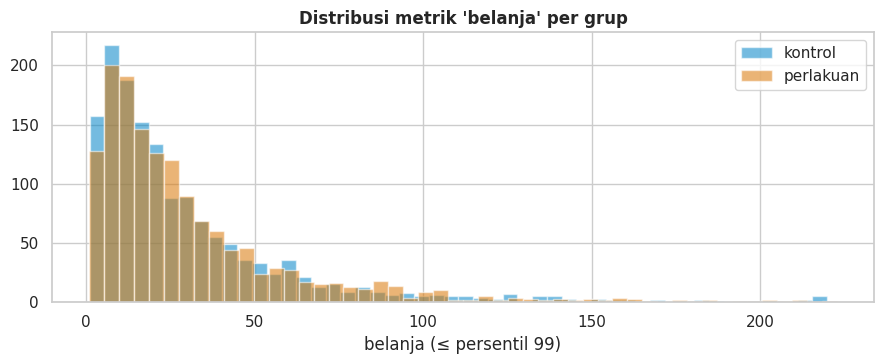

In [4]:
p_srm = srm_check(len(x1), len(x2), EXPECTED_RATIO_G1)

fig, ax = plt.subplots(figsize=(9, 3.8))
if BINARY:
    pd.Series({G1: x1.mean(), G2: x2.mean()}).plot(kind="bar", ax=ax, color=["#0284C7", "#D97706"], rot=0)
    ax.set_ylabel(f"proporsi {METRIC} = 1")
else:
    hi_cut = np.quantile(pop, 0.99)
    for lbl, x, c in [(G1, x1, "#0284C7"), (G2, x2, "#D97706")]:
        ax.hist(x[x <= hi_cut], bins=50, alpha=0.55, color=c, label=lbl)
    ax.set_xlabel(f"{METRIC} (≤ persentil 99)"); ax.legend()
    print(f"\nSkewness {METRIC} = {stats.skew(pop):.2f}  |  mean = {pop.mean():.3f}, median = {np.median(pop):.3f}")
ax.set_title(f"Distribusi metrik '{METRIC}' per grup", fontweight="bold")
plt.tight_layout(); plt.show()

# 📐 5. Komponen 1 — Simulasi Sampling Distribution

Anggap seluruh data sebagai **populasi**, ambil sampel berulang (2.000×) dengan n = 30, 300, 3000, lalu bandingkan **SE empiris** (std dari rata-rata sampel) dengan **SE teori** σ/√n.

Teori: $SE(\bar{x}) = \sigma / \sqrt{n}$ — untuk metrik biner σ = √(p(1−p)).

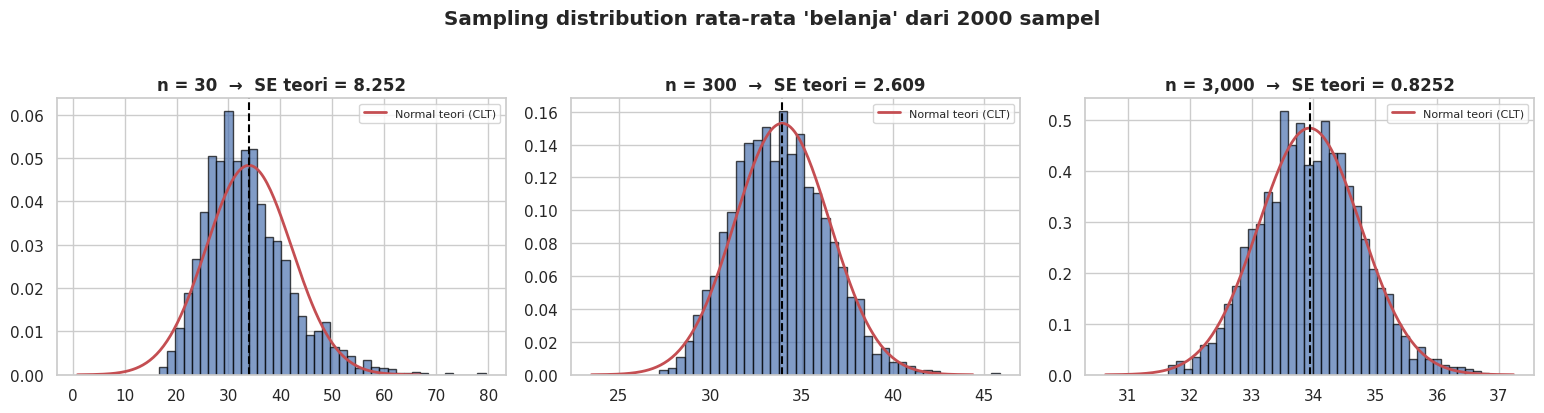

,n,SE empiris,SE teori,skewness x̄
0,30,8.17610,8.25152,0.92264
1,300,2.53761,2.60936,0.29639
2,3000,0.82469,0.82515,0.15048


In [5]:
sampling_distribution(pop, ns=(30, 300, 3000), reps=2000)

**Interpretasi (tulis sendiri):** _Apakah SE empiris ≈ SE teori? Bagaimana bentuk distribusi pada n = 30 vs n = 3000 (lihat skewness x̄)? Apa artinya bagi metrik utama saya — berapa n minimal agar rata-rata sampel stabil/mendekati Normal?_

# 📏 6. Komponen 2 — Confidence Interval: Rumus vs Bootstrap

## 6.1 CI per grup

In [6]:
ci_tbl = ci_per_group({G1: x1, G2: x2}, BINARY)
ci_tbl.round(4)

,grup,n,mean,CI lo,CI hi,metode
0,kontrol,1506,33.4758,31.1005,35.8511,t
1,perlakuan,1494,34.4017,32.2026,36.6009,t


## 6.2 CI selisih 2 grup (G2 − G1): rumus vs bootstrap

- **Rumus:** proporsi → Wald selisih proporsi; numerik → Welch (varians boleh berbeda).
- **Bootstrap:** resampling dengan pengembalian 2.000×, ambil persentil 2.5 dan 97.5 — tanpa asumsi bentuk distribusi.

=== SELISIH RATA-RATA 'belanja' (perlakuan − kontrol) ===
  Selisih teramati : +0.9259   (SE = 1.6502)
  CI rumus 95%     : [-2.3098, +4.1617]
  CI bootstrap 95% : [-2.3555, +4.0355]
  P(selisih > 0) dari bootstrap = 0.708
  Lebar CI → rumus 6.4715 vs bootstrap 6.3910

=== SELISIH MEDIAN (bootstrap) ===
  Median kontrol = 19.900, perlakuan = 21.390
  CI bootstrap 95% selisih median : [-0.0200, +3.4851]  (median tak punya rumus SE sederhana)


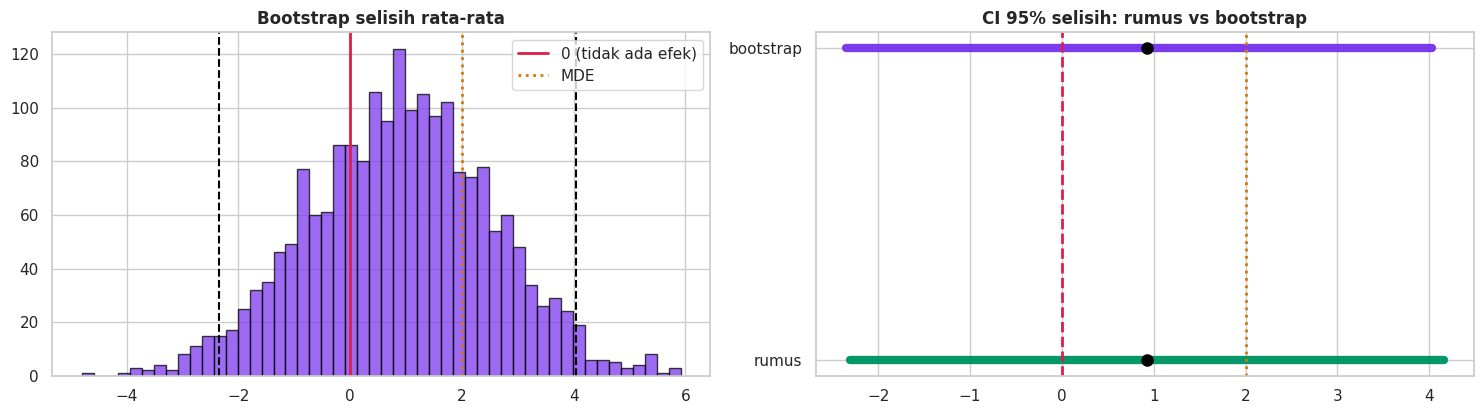

In [7]:
d_hat, se, f_lo, f_hi = ci_diff(x1, x2, BINARY)
boot_mean, boot_med = bootstrap_diff(x1, x2, reps=2000, median=not BINARY)
b_lo, b_hi = np.percentile(boot_mean, [2.5, 97.5])

print(f"=== SELISIH RATA-RATA '{METRIC}' ({G2} − {G1}) ===")
print(f"  Selisih teramati : {d_hat:+.4f}   (SE = {se:.4f})")
print(f"  CI rumus 95%     : [{f_lo:+.4f}, {f_hi:+.4f}]")
print(f"  CI bootstrap 95% : [{b_lo:+.4f}, {b_hi:+.4f}]")
print(f"  P(selisih > 0) dari bootstrap = {(boot_mean > 0).mean():.3f}")
print(f"  Lebar CI → rumus {f_hi-f_lo:.4f} vs bootstrap {b_hi-b_lo:.4f}")

if not BINARY:
    m_lo, m_hi = np.percentile(boot_med, [2.5, 97.5])
    print(f"\n=== SELISIH MEDIAN (bootstrap) ===")
    print(f"  Median {G1} = {np.median(x1):.3f}, {G2} = {np.median(x2):.3f}")
    print(f"  CI bootstrap 95% selisih median : [{m_lo:+.4f}, {m_hi:+.4f}]  (median tak punya rumus SE sederhana)")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
axes[0].hist(boot_mean, bins=50, color="#7C3AED", edgecolor="black", alpha=0.75)
for v in (b_lo, b_hi): axes[0].axvline(v, color="black", ls="--")
axes[0].axvline(0, color="#E11D48", lw=2, label="0 (tidak ada efek)")
axes[0].axvline(MDE if HIGHER_IS_BETTER else -MDE, color="#D97706", ls=":", lw=2, label="MDE")
axes[0].set_title("Bootstrap selisih rata-rata", fontweight="bold"); axes[0].legend()

for i, (lbl, lo, hi, c) in enumerate([("rumus", f_lo, f_hi, "#059669"), ("bootstrap", b_lo, b_hi, "#7C3AED")]):
    axes[1].plot([lo, hi], [i, i], color=c, lw=6); axes[1].plot(d_hat, i, "o", color="black", ms=8)
axes[1].axvline(0, color="#E11D48", ls="--", lw=2)
axes[1].axvline(MDE if HIGHER_IS_BETTER else -MDE, color="#D97706", ls=":", lw=2)
axes[1].set_yticks([0, 1]); axes[1].set_yticklabels(["rumus", "bootstrap"])
axes[1].set_title("CI 95% selisih: rumus vs bootstrap", fontweight="bold")
plt.tight_layout(); plt.show()

**Interpretasi (tulis sendiri):** _Apakah CI rumus dan bootstrap hampir sama? Mengapa (atau mengapa tidak) pada metrik saya? Apakah CI memuat 0? Apa arti lebar CI-nya bagi presisi estimasi?_

# ⚡ 7. Komponen 3 — Power Analysis

Tentukan **MDE** (selisih terkecil yang *penting bagi bisnis*, bukan sekadar yang teramati) di sel Konfigurasi. Lalu jawab tiga pertanyaan:

1. Berapa n per grup yang dibutuhkan untuk mendeteksi MDE tersebut (power 80%, α = 5%)?
2. Dengan n yang tersedia, berapa power yang dicapai?
3. Dengan n yang tersedia, MDE terkecil berapa yang masih terdeteksi dengan power 80%?

=== POWER ANALYSIS (α = 0.05, power target = 0.80) ===
  MDE pilihan               : 2  (effect size = 0.0442, Cohen d)
  n dibutuhkan per grup     : ≈ 8,054
  n tersedia per grup       : 1,506
  Power yang dicapai        : 23%
  MDE terkecil yang terdeteksi (power 80%) dengan data ini : ≈ 4.626

⚠️ Data KURANG (underpowered): hasil 'tidak signifikan' tidak boleh dibaca sebagai 'tidak ada efek'.


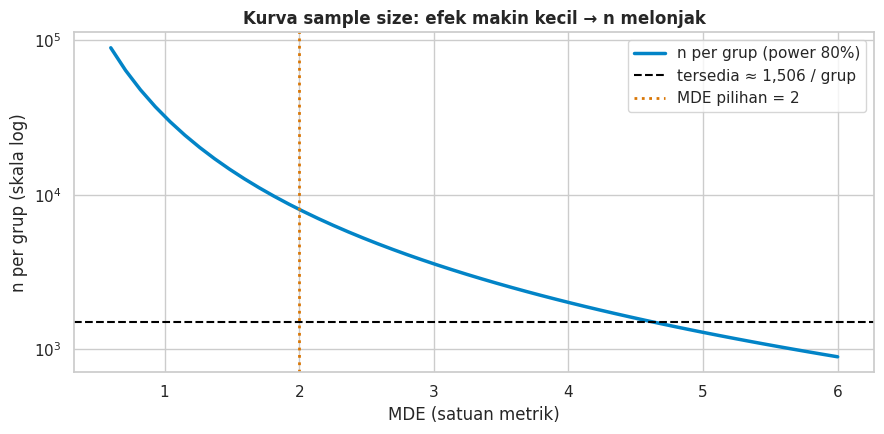

In [8]:
pr = power_report(x1, x2, BINARY, MDE)
print("=== POWER ANALYSIS (α = 0.05, power target = 0.80) ===")
print(f"  MDE pilihan               : {MDE:g}  (effect size = {pr['es']:.4f}, {'Cohen h' if BINARY else 'Cohen d'})")
print(f"  n dibutuhkan per grup     : ≈ {pr['n_need']:,.0f}")
print(f"  n tersedia per grup       : {pr['n_have']:,}")
print(f"  Power yang dicapai        : {pr['achieved']:.0%}")
print(f"  MDE terkecil yang terdeteksi (power 80%) dengan data ini : ≈ {pr['mde_min']:.4g}")
if pr['n_have'] >= pr['n_need']:
    print("\n✅ Data CUKUP untuk mendeteksi MDE pilihan.")
else:
    print("\n⚠️ Data KURANG (underpowered): hasil 'tidak signifikan' tidak boleh dibaca sebagai 'tidak ada efek'.")

power_curve(x1, x2, BINARY, MDE)

**Interpretasi (tulis sendiri):** _Mengapa MDE ini yang saya pilih (alasan bisnis)? Apakah data saya cukup? Jika tidak, berapa tambahan data yang dibutuhkan, atau MDE berapa yang realistis?_

# 🧭 8. Komponen 4 — Rekomendasi Keputusan (Ship or Not)

Keputusan ditentukan oleh **posisi CI selisih terhadap 0 dan MDE**:

| Posisi CI 95% selisih | Keputusan |
|---|---|
| Seluruh CI ≥ MDE | ✅ **Ship** — efek positif dan cukup besar |
| CI > 0 tetapi memuat MDE | 🟡 **Ship dengan catatan** — positif nyata, belum pasti ≥ MDE |
| CI > 0 tetapi seluruhnya < MDE | 🟠 **Signifikan tapi kecil** — timbang biaya vs manfaat |
| CI memuat 0 **dan** MDE | ⏳ **Inconclusive** — data kurang, tambah data |
| CI memuat 0 tetapi < MDE | ⚪ **Tidak ada efek penting** |
| Seluruh CI < 0 | ❌ **Jangan ship** |

In [9]:
label, alasan = keputusan(d_hat, f_lo, f_hi, MDE, HIGHER_IS_BETTER)

print("=== REKOMENDASI ===")
print(f"Metrik utama   : {METRIC}  ({'proporsi' if BINARY else 'rata-rata'}), perbandingan {G2} − {G1}")
print(f"Efek teramati  : {d_hat:+.4f}, CI 95% [{f_lo:+.4f}, {f_hi:+.4f}]  |  MDE = {MDE:g}")
print(f"Kecukupan data : power {pr['achieved']:.0%} untuk MDE pilihan (target 80%)")
print(f"Cek ukuran grup: p-SRM = {p_srm:.4f}")
print(f"\n{label}\n→ {alasan}")

=== REKOMENDASI ===
Metrik utama   : belanja  (rata-rata), perbandingan perlakuan − kontrol
Efek teramati  : +0.9259, CI 95% [-2.3098, +4.1617]  |  MDE = 2
Kecukupan data : power 23% untuk MDE pilihan (target 80%)
Cek ukuran grup: p-SRM = 0.8266

⏳ INCONCLUSIVE
→ CI memuat 0 DAN memuat MDE → data belum cukup (underpowered); tambah data.


### ✏️ Rekomendasi & Catatan Risiko (tulis sendiri)

**Keputusan:** _Ship / Jangan ship / Inconclusive — beserta alasan dengan merujuk CI dan MDE._

**Catatan risiko / keterbatasan:**
- _Apakah data observasional (bukan eksperimen terkontrol)? Adakah confounder yang mungkin menjelaskan selisih?_
- _Apakah ukuran grup seimbang (cek SRM)? Apakah n cukup (power)?_
- _Apakah outlier/skewness memengaruhi mean? Bagaimana hasil selisih median?_
- _Berapa banyak metrik/perbandingan yang saya uji (risiko false positive bila banyak)?_

**Langkah lanjutan:** _..._

# ✅ 9. Checklist Submit Milestone 3

- [ ] Simulasi sampling distribution 1 metrik utama (SE empiris vs teori)
- [ ] CI rumus + bootstrap CI, dibandingkan
- [ ] CI selisih 2 grup penting
- [ ] Power analysis untuk MDE pilihan + evaluasi kecukupan data
- [ ] Rekomendasi keputusan + catatan risiko
- [ ] `DATA_PATH`, `METRIC`, `G1/G2`, dan `MDE` sudah diganti ke dataset Anda (bukan data demo)
- [ ] README diperbarui, commit: `"Milestone 3: sampling distribution & CI"`
- [ ] Link GitHub dikumpulkan via LMS **sebelum Modul 12**